# Telecom Customer Churn Analytics & Prediction

## Notebook 2: Exploratory Data Analysis (EDA)

### Objective

The objective of this notebook is to explore the cleaned telecom customer dataset to understand customer behavior, identify churn patterns, discover relationships between variables, and generate business insights that will support feature engineering and predictive modeling.

This notebook includes:

- Univariate Analysis
- Bivariate Analysis
- Multivariate Analysis
- Correlation Analysis
- Business Insights

##  Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [36]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8,8)

## Load Clean Dataset

In [9]:
df = pd.read_csv("../Data/processed/telecom_churn_clean.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Quick Validation

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


## Exploratory Data Analysis

## 📊 Visualization 1: Churn Distribution
#### Business Question
How many customers have churned, and how many have stayed?
  

In [19]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [21]:
(df['Churn'].value_counts(normalize=True)*100).round(2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [30]:
# Custom color palette matching a professional tech aesthetic
palette = {"No": "#2a9d8f", "Yes": "#e76f51"}

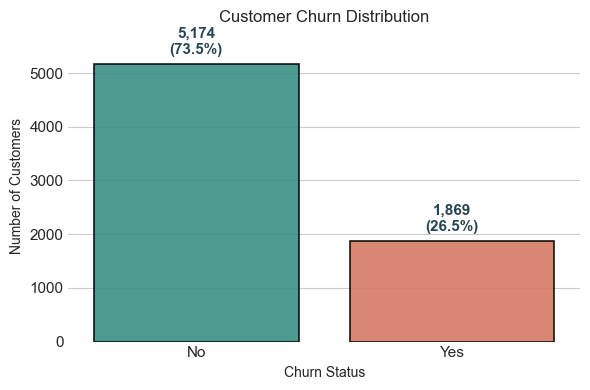

In [48]:
plt.figure(figsize=(6,4))

ax=sns.countplot(
    data=df,
    x="Churn",
    palette=palette,
    hue="Churn",
    legend=False,
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
total = len(df)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        percentage = (height / total) * 100
        ax.annotate(
            f'{int(height):,}\n({percentage:.1f}%)',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', 
            va='bottom', 
            fontsize=11, 
            fontweight='bold',
            color='#264653',
            xytext=(0, 5),
            textcoords='offset points'
        )
sns.despine(left=True, bottom=True)
ax.tick_params(axis='both', which='both', length=0, labelsize=11)
plt.ylim(0, max(df['Churn'].value_counts()) * 1.12)
plt.tight_layout()
plt.show()

## Customer Churn Distribution Analysis
### Key Data Points
* **Retained Customers ("No"):** Approximately **5,100 to 5,200** customers have not churned.
* **Churned Customers ("Yes"):** Approximately **1,800 to 1,900** customers have churned.

---

### Core Insights

* **Class Imbalance:** There is a significant class imbalance in the dataset. Retained customers vastly outnumber churned customers by a ratio of roughly **2.7:1**.
* **Churn Rate:** Based on the visual metrics, the customer churn rate sits at approximately **26% to 27%**. 
* **Business Impact:** While the majority of the customer base remains loyal, losing more than a quarter of the total customer pool highlights a substantial retention challenge that requires targeted intervention strategies.

## 📊 Visualization 2: Gender Distribution
#### Business Question
What is the gender distribution of telecom customers?

In [53]:
df["gender"].value_counts()

gender
Male      3555
Female    3488
Name: count, dtype: int64

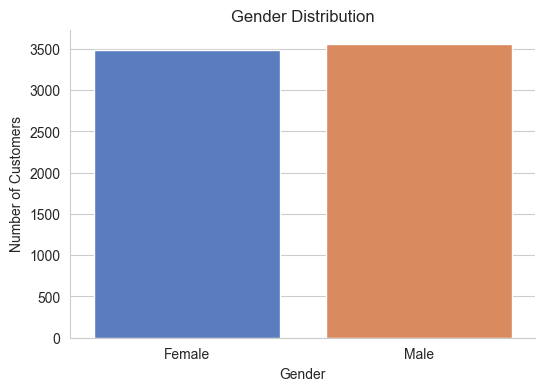

In [61]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="gender",palette="muted",hue ='gender')

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
sns.despine()
plt.show()

### Gender Distribution Analysis

#### Key Data Points
* **Male Customers:** **3,555**
* **Female Customers:** **3,488**
---

#### Core Insights

* **Balanced Distribution:** The customer base is nearly perfectly balanced between genders, with males making up roughly **50.5%** and females making up **49.5%** of the dataset.
* **Symmetrical Grouping:** There is no significant demographic skew or imbalance here, which means any high churn rates or purchasing behaviors observed elsewhere in the data are likely driven by factors other than gender alone.

## 📊 Visualization 3: Contract Distribution
#### Business Question
Which contract type do customers prefer?

In [70]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

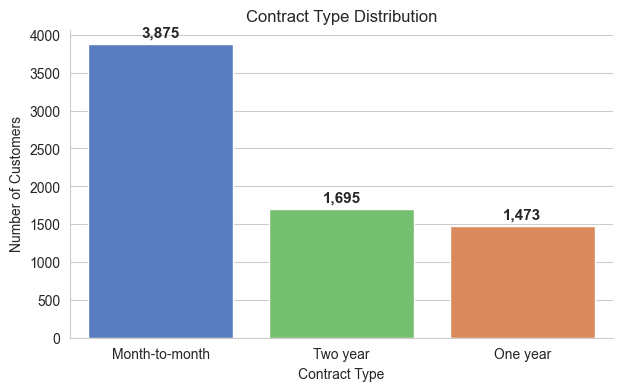

In [78]:
plt.figure(figsize=(7,4))

ax=sns.countplot(
    data=df,
    x="Contract",
    order=df["Contract"].value_counts().index,
    palette="muted",
    hue='Contract'
)

plt.title("Contract Type Distribution")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height):,}',                  # The text to display (formatted with commas)
            (p.get_x() + p.get_width() / 2., height),  # X and Y coordinates
            ha='center',                         # Center text horizontally
            va='bottom',                         # Position text above the bar line
            fontsize=11, 
            fontweight='bold',
            xytext=(0, 3),                       # Subtle upward offset
            textcoords='offset points'
        )

# Remove unnecessary outer borders for a cleaner look
sns.despine()
plt.show()

### Contract Type Distribution Analysis

#### Key Data Points
* **Month-to-month:** **3,875** customers
* **Two year:** **1,695** customers
* **One year:** **1,473** customers
* **Total Sample Size:** **7,043** total customers

---

#### Core Insights

* **Dominance of Short-Term Contracts:** The vast majority of customers (**55%**) are on a flexible Month-to-month contract plan. 
* **High Volatility Risk:** Because Month-to-month contracts have no long-term commitment, more than half of the user base is actively fluid and can cancel at any given time. This indicates a high structural risk for rapid customer churn.
* **Long-Term Retention Benchmarks:** Combined long-term contracts (One year and Two year) make up the remaining **45%** of the user base ($3,168$ customers), providing a stable core revenue baseline compared to the highly transactional month-to-month segment.

## 📊 Visualization 4: Internet Service Distribution
### Business Question
Which internet service is most popular?

In [84]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

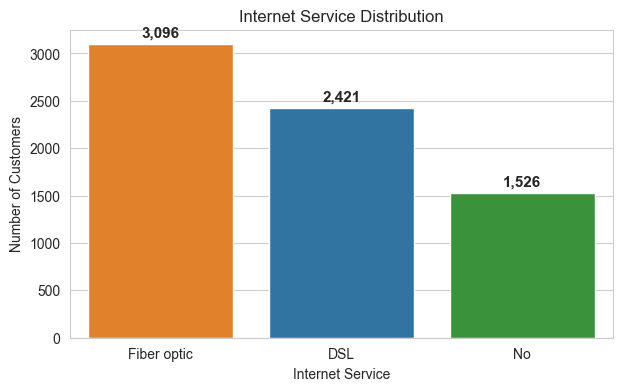

In [90]:
plt.figure(figsize=(7,4))

ax=sns.countplot(
    data=df,
    x="InternetService",
    order=df["InternetService"].value_counts().index,hue='InternetService'
)

plt.title("Internet Service Distribution")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height):,}',                  # The text to display (formatted with commas)
            (p.get_x() + p.get_width() / 2., height),  # X and Y coordinates
            ha='center',                         # Center text horizontally
            va='bottom',                         # Position text above the bar line
            fontsize=11, 
            fontweight='bold',
            xytext=(0, 3),                       # Subtle upward offset
            textcoords='offset points'
        )
plt.show()

### Internet Service Distribution Analysis

#### Key Data Points
* **Fiber optic:** **3,096** customers
* **DSL:** **2,421** customers
* **No Internet Service:** **1,526** customers
* **Total Sample Size:** **7,043** total customers

---

#### Core Insights

* **High Digital Adoption:** The vast majority of customers (**78.3%**) use the company's internet services (either Fiber optic or DSL), making connectivity products a central driver of the core business.
* **Fiber Optic Preference:** Fiber optic is the most popular connection type, accounting for roughly **44.0%** of the user base. Earlier SQL analysis showed that Fiber Optic customers also have the highest churn rate and contribute the largest revenue loss.
* **Legacy vs. Non-Users:** Traditional DSL accounts for **34.4%** of connections, while a smaller but notable segment (**21.7%**) does not subscribe to any internet service at all, identifying a potential target audience for cross-selling initiatives.

## 📊 Visualization 5: Payment Method Distribution
### Business Question
Which payment method is most preferred by customers?

In [97]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

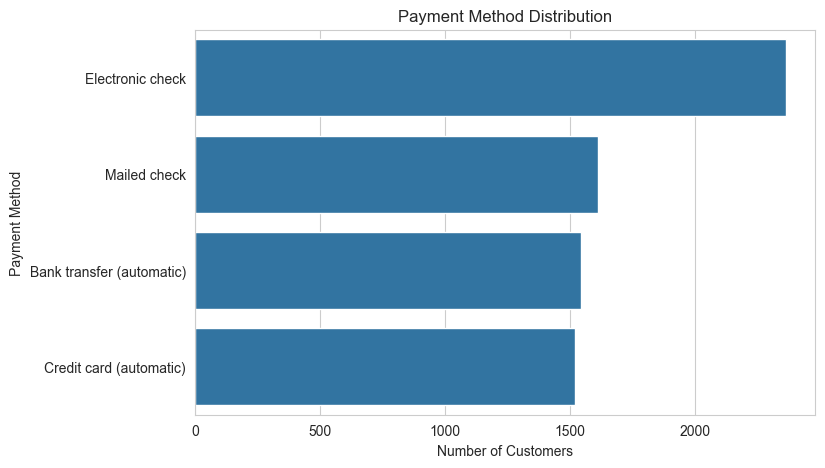

In [99]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    y="PaymentMethod",
    order=df["PaymentMethod"].value_counts().index
)

plt.title("Payment Method Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Payment Method")

plt.show()

### Payment Method Distribution Analysis
#### Key Data Points
* **Electronic check:** **2,365** customers
* **Mailed check:** **1,612** customers
* **Bank transfer (automatic):** **1,544** customers
* **Credit card (automatic):** **1,522** customers
* **Total Sample Size:** **7,043** total customers

---

#### Core Insights

* **Popularity of Electronic Checks:** Electronic check is the single most dominant payment method, capturing roughly **33.6%** of the entire customer base.
* From our SQL analysis, we already know customers using Electronic Check also have the highest churn rate (≈45%).                      
* **Manual vs. Automatic Billing:** Manual payment methods (Electronic check and Mailed check) combined account for **56.5%** ($3,977$ customers) of the pool. Because manual transactions require active effort each month, this large cohort represents higher structural churn risk compared to automated users.
* **Balanced Automation Baseline:** The automated options—Bank transfers (**21.9%**) and Credit cards (**21.6%**)—share nearly identical adoption metrics, forming a stable core of customers who are typically less prone to accidental payment defaults.

## 📊 Visualization 6: Monthly Charges Distribution
#### Business Question
How are monthly charges distributed among customers?

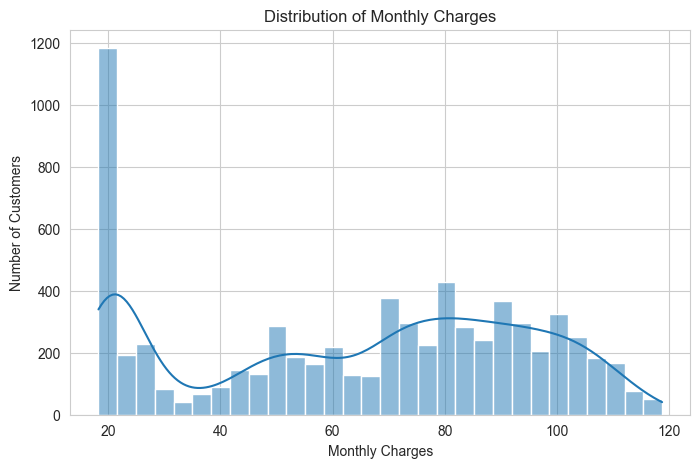

In [106]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    bins=30,
    kde=True
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

### Distribution of Monthly Charges Analysis
#### Key Data Observations
* **Highest Concentration Peak:** A massive spike of nearly **1,200 customers** is clustered at the low end of the spectrum around **\$20** per month.
* **Secondary Broad Peak:** A wide, multi-modal distribution spans between **\$70 and \$100** per month, peaking notably around the **\$80** mark with over 400 customers.
* **Value Range:** Monthly billing ranges from a minimum of approximately **\$18** up to a maximum near **\$120**.

---

#### Core Insights

* **Bimodal Customer Base:** The distribution reveals two primary types of consumers: a large budget-conscious/entry-level cohort at the minimum price tier,  and  a large premium cohort paying premium tier prices (\$70–\$100) for more extensive bundles (likely fiber optic and extra services).
* **Low Density Mid-Tier:** There is a distinctive valley between **\$30 and \$40**, indicating that very few customers choose mid-tier subscription options. The business tends to push users either to baseline standalone accounts or full high-speed/entertainment suites.
* **Revenue Strategy Target:** Because a vast volume of users sits at the \$20 baseline, even marginal value add-ons or minor price optimizations targeted at this low-tier group could drastically shift overall revenue metrics.

## 📊 Visualization 7: Churn vs Gender
#### Business Question:
Does gender influence customer churn?

In [126]:
pd.crosstab(df["gender"], df["Churn"])

Churn,No,Yes
gender,,
Female,2549,939
Male,2625,930


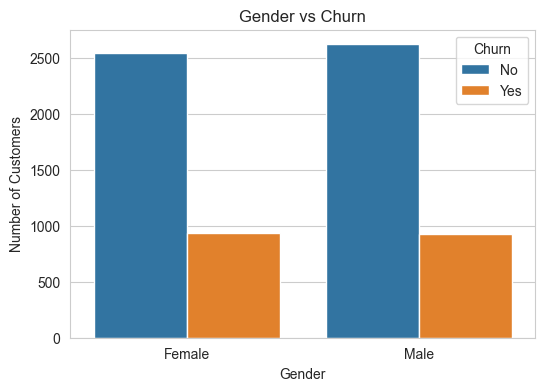

In [120]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="gender",
    hue="Churn"
)

plt.title("Gender vs Churn")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.legend(title="Churn")

plt.show()

### Business Insight
- Male and female customers exhibit very similar churn patterns.
- Gender does not appear to be a strong predictor of churn.
- Later, the machine learning model will determine the actual importance of this feature.

## 📊 Visualization 8: Senior Citizen vs Churn
#### Business Question

Do senior citizens churn more frequently than non-senior citizens?

In [134]:
(
pd.crosstab(df["SeniorCitizen"], df["Churn"], normalize="index")
*100
).round(2)

Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


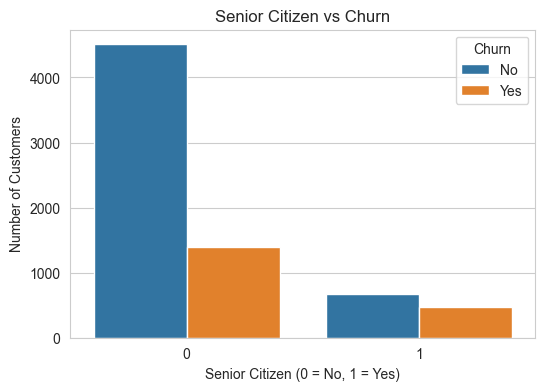

In [136]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="SeniorCitizen",
    hue="Churn"
)

plt.title("Senior Citizen vs Churn")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.legend(title="Churn")

plt.show()

### Business Insight
- Senior citizens have a noticeably higher churn rate.
- They may require specialized customer support, simplified plans, or loyalty benefits.
- This suggests SeniorCitizen is an important predictive feature.

## 📊 Visualization 9: Contract Type vs Churn 
#### Business Question

Which contract type has the highest churn?

In [140]:
pd.crosstab(df["Contract"], df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


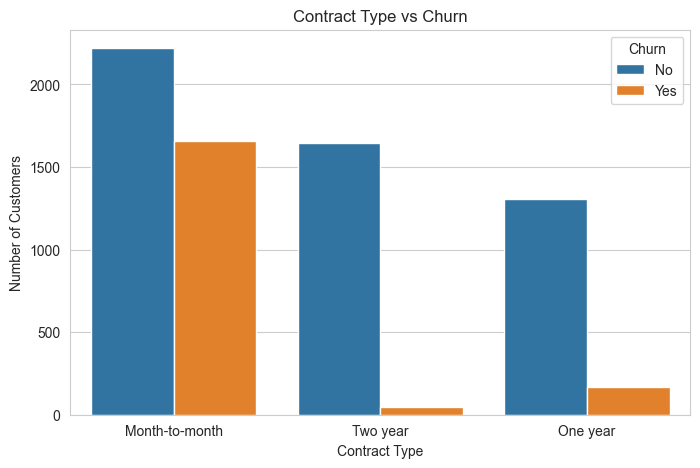

In [142]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    order=df["Contract"].value_counts().index
)

plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.legend(title="Churn")

plt.show()

### Business Insight

This visualization clearly shows:

- Month-to-Month customers are the most likely to churn.
- Long-term contracts significantly improve customer retention.
- Contract type is one of the strongest predictors of churn.

 **Business Recommendation**

Encourage Month-to-Month customers to switch to annual or two-year plans through discounts or loyalty incentives.

## 📊 Visualization 10: Internet Service vs Churn 
#### Business Question

Does internet service type affect customer churn?

In [153]:
pd.crosstab(df["InternetService"], df["Churn"])

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [155]:
(
pd.crosstab(df["InternetService"], df["Churn"], normalize="index")
*100
).round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


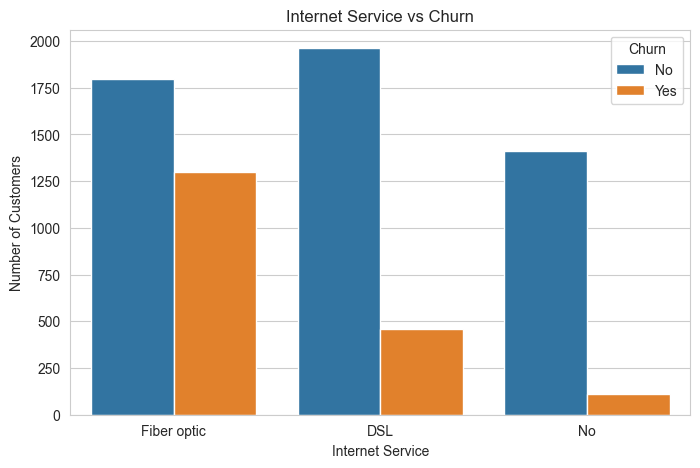

In [157]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn",
    order=df["InternetService"].value_counts().index
)

plt.title("Internet Service vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.legend(title="Churn")

plt.show()

### Business Insight
- Fiber Optic customers have the highest churn rate.
- Despite generating the highest revenue, they are also the highest-risk customers.
- This indicates possible issues with pricing, customer expectations, or service quality.

## 📊 Visualization 11: Payment Method vs Churn
#### Business Question

Does the customer's payment method influence churn?

In [161]:
pd.crosstab(df["PaymentMethod"], df["Churn"])

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [163]:
(
pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index")
*100
).round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


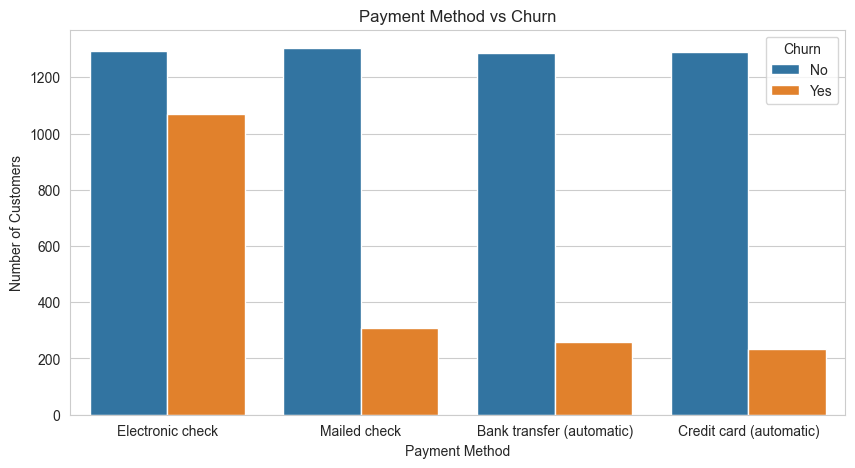

In [167]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn",
    order=df["PaymentMethod"].value_counts().index
)

plt.title("Payment Method vs Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=0)

plt.legend(title="Churn")

plt.show()

### Business Insight
- Electronic Check customers have the highest churn.
- Automatic payment methods show significantly lower churn.
- Promoting AutoPay could improve customer retention.

## 📊 Visualization 12: Tenure vs Churn 
#### Business Question

How does customer tenure affect churn?

In [172]:
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


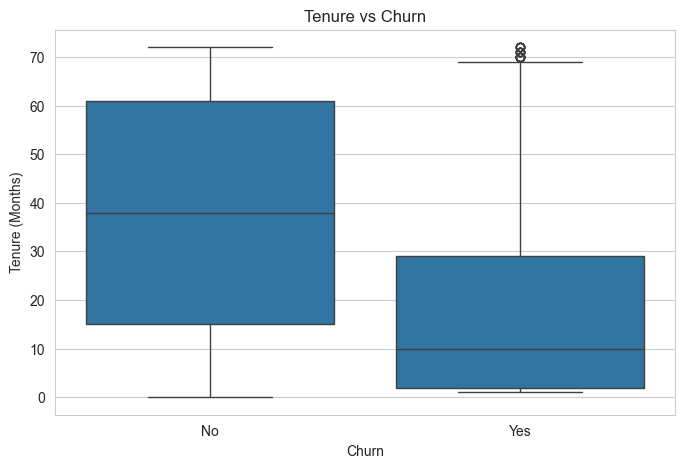

In [174]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

### Business Insight
- Customers who churn generally have much lower tenure.
- Long-term customers are far more likely to remain with the company.
- Tenure is expected to be one of the most important ML features.

## 📊 Visualization 13: Monthly Charges vs Total Charges.
#### Business Question

Is there a relationship between Monthly Charges and Total Charges?

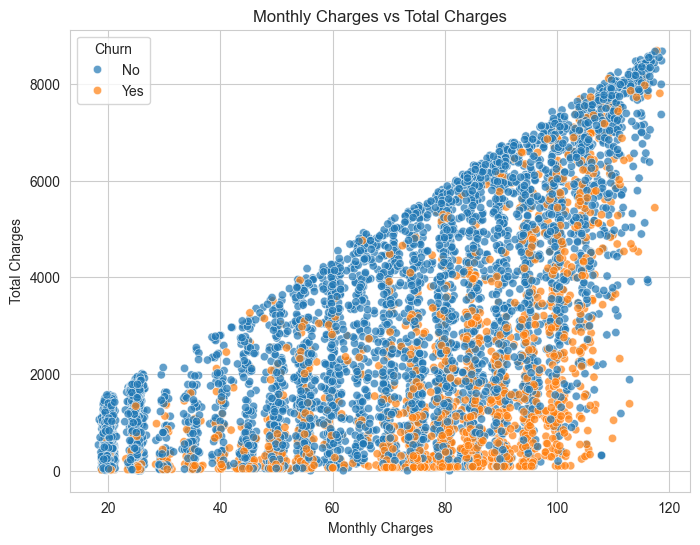

In [179]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="MonthlyCharges",
    y="TotalCharges",
    hue="Churn",
    alpha=0.7
)

plt.title("Monthly Charges vs Total Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Total Charges")

plt.show()

### Business Insight
- Customers staying longer naturally accumulate larger total bills.
- Recently acquired high-paying customers appear more likely to churn.

## 📊 Visualization 14: Correlation Heatmap
Since our dataset contains many categorical columns, we'll first compute correlations using only numerical features.

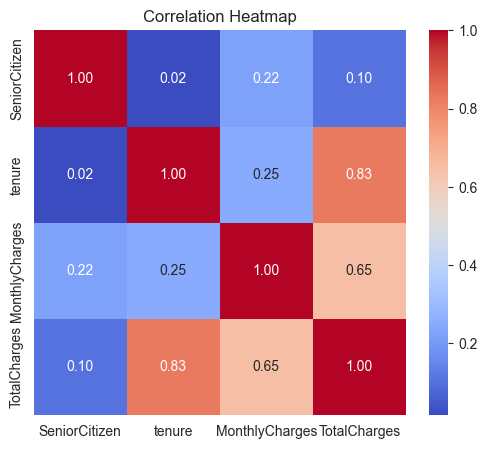

In [183]:
plt.figure(figsize=(6,5))

sns.heatmap(
    df.select_dtypes(include=["int64","float64"]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

## Business Insight
- TotalCharges and tenure have a strong positive correlation.
- MonthlyCharges has a moderate relationship with TotalCharges.
- SeniorCitizen has little linear correlation with the other numerical variables.

# **Business Insights Summary**

# Key Business Insights from Exploratory Data Analysis

## Customer Profile
- Customer base is evenly distributed across gender.
- Most customers are on Month-to-Month contracts.
- Fiber Optic is the most popular internet service.
- Electronic Check is the most common payment method.

## Major Churn Drivers
- Month-to-Month customers have the highest churn rate.
- Fiber Optic customers churn significantly more than DSL users.
- Electronic Check users show the highest customer attrition.
- Senior citizens are more likely to churn.
- Customers with shorter tenure have a higher probability of leaving.

## Revenue Insights
- Long-term customers contribute significantly more Total Charges.
- High Monthly Charges alone do not guarantee customer retention.
- Retaining early-stage customers could substantially improve customer lifetime value.

## Key Features for Machine Learning
Based on EDA, the following variables appear to be strong predictors of churn:

- Contract
- InternetService
- PaymentMethod
- tenure
- MonthlyCharges
- TotalCharges
- SeniorCitizen